In [12]:
import numpy as np
marks = np.array([65, 70, 75, 80, 90])
print("Mean:", np.mean(marks))
print("Median:", np.median(marks))

Mean: 76.0
Median: 75.0


In [13]:
import numpy as np
marks = np.array([65, 70, 75, 80, 90])
print("SampleStandardDeviation:", np.std(marks, ddof=1))

SampleStandardDeviation: 9.617692030835672


In [14]:
import numpy as np
salary = [20000, 30000, 35000, 40000, 50000]
print("25th:", np.percentile(salary, 25))
print("50th:", np.percentile(salary, 50))
print("75th:", np.percentile(salary, 75))

25th: 30000.0
50th: 35000.0
75th: 40000.0


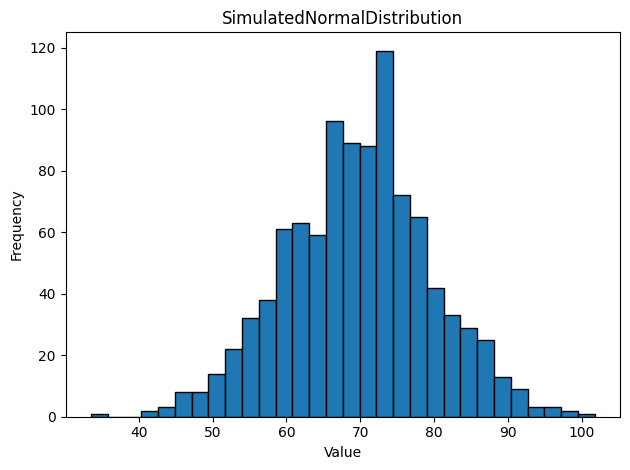

In [15]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
values = rng.normal(loc=70, scale=10, size=1000)

plt.hist(values, bins=30, edgecolor="black")
plt.title("SimulatedNormalDistribution")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

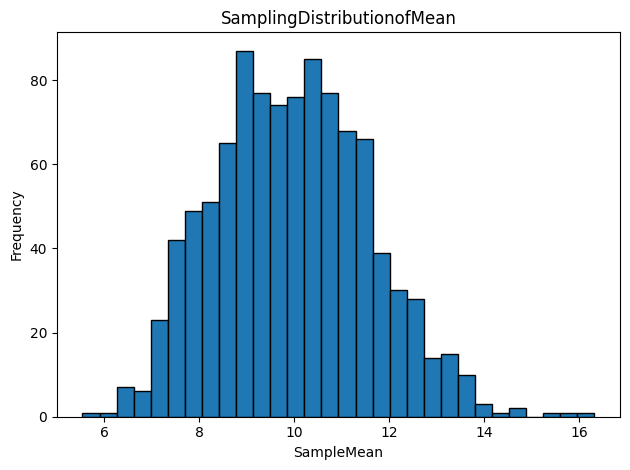

In [16]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
population = rng.exponential(scale=10, size=100000)
sample_means = []

for _ in range(1000):
    sample = rng.choice(population, size=40, replace=True)
    sample_means.append(sample.mean())

plt.hist(sample_means, bins=30, edgecolor="black")
plt.title("SamplingDistributionofMean")
plt.xlabel("SampleMean")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [17]:
import numpy as np
from scipy import stats

scores = np.array([65, 70, 75, 80, 85, 90])
mean = scores.mean()
sem = stats.sem(scores)

interval = stats.t.interval(
    confidence=0.95,
    df=len(scores) - 1,
    loc=mean,
    scale=sem
)

print("Mean:", mean)
print("95%CI:", interval)

Mean: 77.5
95%CI: (np.float64(67.68342846509839), np.float64(87.31657153490161))


In [18]:
from scipy import stats

marks = [70, 75, 80, 85, 90, 72, 78, 82, 88, 95]
result = stats.ttest_1samp(marks, popmean=75)

print("TStatistic:", result.statistic)
print("PValue:", result.pvalue)

TStatistic: 2.5419170710158574
PValue: 0.03161119566937953


In [19]:
from scipy import stats

group_a = [60, 65, 70, 72, 75, 68]
group_b = [70, 75, 78, 80, 82, 76]

result = stats.ttest_ind(group_a, group_b, equal_var=False)

print("TStatistic:", result.statistic)
print("PValue:", result.pvalue)

TStatistic: -3.0687275972126105
PValue: 0.012566556975316683


In [20]:
visitors_a = 1000
conversions_a = 120
visitors_b = 1000
conversions_b = 150

rate_a = conversions_a / visitors_a
rate_b = conversions_b / visitors_b

print("A:", rate_a * 100, "%")
print("B:", rate_b * 100, "%")
print("AbsoluteLift:", (rate_b - rate_a) * 100, "percentagepoints")
print("RelativeLift:", (rate_b / rate_a - 1) * 100, "%")

A: 12.0 %
B: 15.0 %
AbsoluteLift: 3.0 percentagepoints
RelativeLift: 25.0 %


In [21]:
import numpy as np
from scipy.stats import norm

conversions = np.array([120, 150])
visitors = np.array([1000, 1000])

p1 = conversions[0] / visitors[0]
p2 = conversions[1] / visitors[1]

pooled = conversions.sum() / visitors.sum()
se = np.sqrt(pooled * (1 - pooled) * (1 / visitors[0] + 1 / visitors[1]))

z = (p2 - p1) / se
p_value = 2 * norm.sf(abs(z))

print("ZStatistic:", z)
print("PValue:", p_value)

ZStatistic: 1.963049807622355
PValue: 0.04964038686536878


A/B TEST REPORT
  Variant  Visitors  Conversions  Conversion_Rate
0       A      1000          120             0.12
1       B      1000          150             0.15
Absolute Lift: 3.0 percentage points
Relative Lift: 25.0 %
Z Statistic: 1.963
P Value: 0.0496
Approx. 95% Difference CI: (np.float64(0.0001), np.float64(0.0599))
Reject the null hypothesis at alpha = 0.05


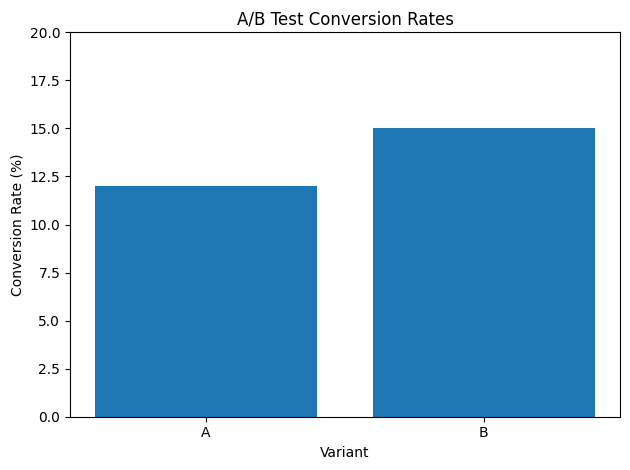

In [22]:
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt

# Fictional experiment data
df = pd.DataFrame({
    "Variant": ["A", "B"],
    "Visitors": [1000, 1000],
    "Conversions": [120, 150]
})

df["Conversion_Rate"] = df["Conversions"] / df["Visitors"]

rate_a = df.loc[0, "Conversion_Rate"]
rate_b = df.loc[1, "Conversion_Rate"]
n_a = df.loc[0, "Visitors"]
n_b = df.loc[1, "Visitors"]
c_a = df.loc[0, "Conversions"]
c_b = df.loc[1, "Conversions"]

absolute_lift = rate_b - rate_a
relative_lift = (rate_b / rate_a - 1)

# Pooled standard error for H0 test
pooled = (c_a + c_b) / (n_a + n_b)
se_null = np.sqrt(pooled * (1 - pooled) * (1 / n_a + 1 / n_b))
z = absolute_lift / se_null
p_value = 2 * norm.sf(abs(z))

# Unpooled standard error for approximate difference CI
se_diff = np.sqrt(rate_a * (1 - rate_a) / n_a + rate_b * (1 - rate_b) / n_b)
ci_low = absolute_lift - 1.96 * se_diff
ci_high = absolute_lift + 1.96 * se_diff

print("A/B TEST REPORT")
print(df)
print("Absolute Lift:", round(absolute_lift * 100, 2), "percentage points")
print("Relative Lift:", round(relative_lift * 100, 2), "%")
print("Z Statistic:", round(z, 4))
print("P Value:", round(p_value, 4))
print("Approx. 95% Difference CI:", (round(ci_low, 4), round(ci_high, 4)))

if p_value < 0.05:
    print("Reject the null hypothesis at alpha = 0.05")
else:
    print("Insufficient evidence to reject the null at alpha = 0.05")

plt.bar(df["Variant"], df["Conversion_Rate"] * 100)
plt.title("A/B Test Conversion Rates")
plt.xlabel("Variant")
plt.ylabel("Conversion Rate (%)")
plt.ylim(0, 20)
plt.tight_layout()
plt.savefig("ab_test_result.png", dpi=180)
plt.show()

df.to_csv("ab_test_report.csv", index=False)